In [ ]:
# 33. Implement an Autoencoder-based anomaly detection system to identify 
# unusual energy consumption patterns using an Energy Consumption 
# dataset. Perform the following steps: 
# a. Import Libraries:  
# b. Dataset Access: Load the energy consumption dataset containing 
# electricity usage records and select relevant numerical features. 
# c. Data Preprocessing: Handle missing values, normalize energy 
# consumption values and prepare the training and testing datasets. 
# d. Encoder Implementation: Build an encoder network using Dense layers 
# to convert energy consumption data into a compressed latent 
# representation. 
# e. Decoder Implementation: Build a decoder network to reconstruct the 
# original energy consumption values from the latent representation. 
# f. Model Compilation: Compile the Autoencoder using the Adam 
# optimizer, MSE loss function and suitable evaluation metrics. 
# g. Anomaly Detection: Calculate reconstruction errors and identify 
# unusual energy consumption patterns using a predefined or 
# validation-based threshold. 
# h. Output: Display actual and reconstructed energy consumption values, 
# reconstruction error graph and detected abnormal consumption patterns.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler

# Download dataset directly from UCI
url = "https://archive.ics.uci.edu/static/public/374/appliances+energy+prediction.zip"

data = pd.read_csv(url, compression='zip', parse_dates=['date'])

print(data.head())
print("Dataset shape:", data.shape)


                 date  Appliances  lights     T1       RH_1    T2       RH_2  \
0 2016-01-11 17:00:00          60      30  19.89  47.596667  19.2  44.790000   
1 2016-01-11 17:10:00          60      30  19.89  46.693333  19.2  44.722500   
2 2016-01-11 17:20:00          50      30  19.89  46.300000  19.2  44.626667   
3 2016-01-11 17:30:00          50      40  19.89  46.066667  19.2  44.590000   
4 2016-01-11 17:40:00          60      40  19.89  46.333333  19.2  44.530000   

      T3       RH_3         T4  ...         T9   RH_9     T_out  Press_mm_hg  \
0  19.79  44.730000  19.000000  ...  17.033333  45.53  6.600000        733.5   
1  19.79  44.790000  19.000000  ...  17.066667  45.56  6.483333        733.6   
2  19.79  44.933333  18.926667  ...  17.000000  45.50  6.366667        733.7   
3  19.79  45.000000  18.890000  ...  17.000000  45.40  6.250000        733.8   
4  19.79  45.000000  18.890000  ...  17.000000  45.40  6.133333        733.9   

   RH_out  Windspeed  Visibility  Tdew

In [2]:

# Select energy consumption and related features
X = data[['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2']]

# Handle missing values
X = X.fillna(X.mean())

print(X.head())


   Appliances  lights     T1       RH_1    T2       RH_2
0          60      30  19.89  47.596667  19.2  44.790000
1          60      30  19.89  46.693333  19.2  44.722500
2          50      30  19.89  46.300000  19.2  44.626667
3          50      40  19.89  46.066667  19.2  44.590000
4          60      40  19.89  46.333333  19.2  44.530000


In [3]:

# Normalize data
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

# Split into training and testing data
split = int(0.8 * len(X))

X_train = X[:split]
X_test = X[split:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (15788, 6)
Testing data: (3947, 6)


In [4]:

# Build Autoencoder
autoencoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(6,)),
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(2, activation='relu'),
    tf.keras.layers.Dense(4, activation='relu'),
    tf.keras.layers.Dense(6, activation='sigmoid')
])

# Compile model
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

autoencoder.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 4)                   │              28 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 2)                   │              10 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 4)                   │              12 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 6)                   │              30 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 80 (320.00 B)

 Trainable params: 80 (320.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:

# Train Autoencoder
history = autoencoder.fit(
    X_train, X_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)


Epoch 1/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.0691 - mae: 0.2118 - val_loss: 0.0550 - val_mae: 0.1900
Epoch 2/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0443 - mae: 0.1691 - val_loss: 0.0373 - val_mae: 0.1588
Epoch 3/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0308 - mae: 0.1425 - val_loss: 0.0275 - val_mae: 0.1387
Epoch 4/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0233 - mae: 0.1261 - val_loss: 0.0219 - val_mae: 0.1262
Epoch 5/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0190 - mae: 0.1154 - val_loss: 0.0186 - val_mae: 0.1173
Epoch 6/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0164 - mae: 0.1077 - val_loss: 0.0166 - val_mae: 0.1105
Epoch 7/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0148 - mae: 0.1020 - val_loss: 0.0152 - val_mae: 0.1052
Epoch 8/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0138 - mae: 0.0975 - val_loss: 0.0143 - val_mae: 0.1010
Epoch 9/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - lo

In [6]:

# Reconstruct test data
reconstructed = autoencoder.predict(X_test)

# Calculate reconstruction error
errors = np.mean((X_test - reconstructed) ** 2, axis=1)

# Set threshold using training errors
train_reconstructed = autoencoder.predict(X_train)
train_errors = np.mean((X_train - train_reconstructed) ** 2, axis=1)

threshold = np.percentile(train_errors, 95)

# Detect anomalies
predictions = errors > threshold

print("Threshold:", threshold)
print("Detected anomalies:", np.sum(predictions))


124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
494/494 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Threshold: 0.03277452440174132
Detected anomalies: 2341


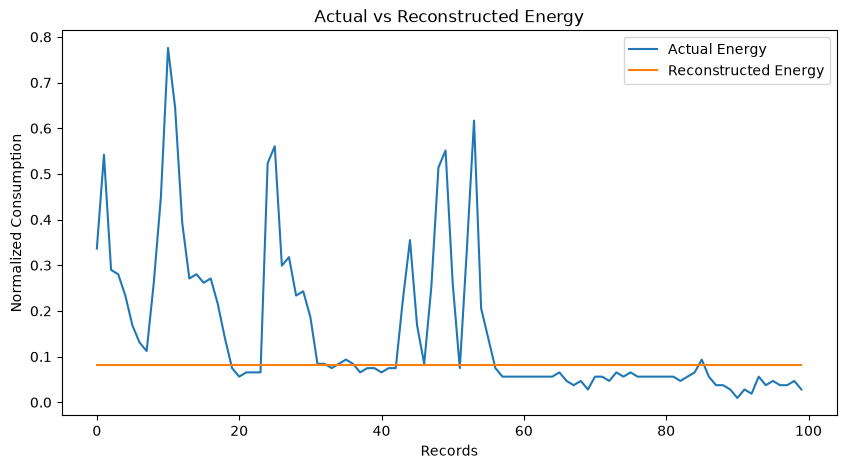

In [7]:

# Compare actual and reconstructed energy
plt.figure(figsize=(10, 5))

plt.plot(X_test[:100, 0], label='Actual Energy')
plt.plot(reconstructed[:100, 0], label='Reconstructed Energy')

plt.title('Actual vs Reconstructed Energy')
plt.xlabel('Records')
plt.ylabel('Normalized Consumption')
plt.legend()
plt.show()


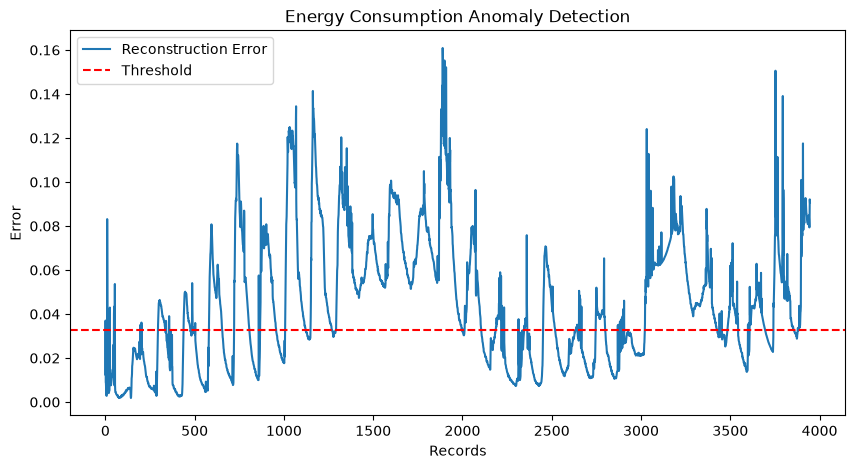

In [8]:

# Plot reconstruction errors
plt.figure(figsize=(10, 5))

plt.plot(errors, label='Reconstruction Error')
plt.axhline(threshold, color='red', linestyle='--', label='Threshold')

plt.title('Energy Consumption Anomaly Detection')
plt.xlabel('Records')
plt.ylabel('Error')
plt.legend()
plt.show()


In [9]:

# Display detected abnormal patterns
print("Detected abnormal records:")

for i in range(len(predictions)):
    if predictions[i]:
        print("Record", i, "- Abnormal Consumption")


Detected abnormal records:
Record 1 - Abnormal Consumption
Record 10 - Abnormal Consumption
Record 11 - Abnormal Consumption
Record 24 - Abnormal Consumption
Record 25 - Abnormal Consumption
Record 48 - Abnormal Consumption
Record 49 - Abnormal Consumption
Record 53 - Abnormal Consumption
Record 195 - Abnormal Consumption
Record 201 - Abnormal Consumption
Record 202 - Abnormal Consumption
Record 203 - Abnormal Consumption
Record 204 - Abnormal Consumption
Record 295 - Abnormal Consumption
Record 296 - Abnormal Consumption
Record 297 - Abnormal Consumption
Record 298 - Abnormal Consumption
Record 299 - Abnormal Consumption
Record 300 - Abnormal Consumption
Record 301 - Abnormal Consumption
Record 302 - Abnormal Consumption
Record 303 - Abnormal Consumption
Record 304 - Abnormal Consumption
Record 305 - Abnormal Consumption
Record 306 - Abnormal Consumption
Record 307 - Abnormal Consumption
Record 308 - Abnormal Consumption
Record 309 - Abnormal Consumption
Record 310 - Abnormal Consumpt